# ANN (MLP) | TON_IoT | target: `label` (binary)
Tayyab (SP24-BCS-004). Settings and decisions are tracked in `AUDIT_LOG.md`; hyperparameter sources are in `HYPERPARAMETER_SOURCES.md` (both in the project root).

Plan: 20% test set (stratified), stratified 5-fold validation on the other 80%, hyperparameters fixed from papers (no tuning), test set used once.

## 1. Imports and setup
**Q1.** Import the libraries and set a global `RANDOM_STATE`.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             log_loss, matthews_corrcoef, confusion_matrix, classification_report)

# max_iter = number of epochs from the paper; sklearn warns that the loss is still falling after the last epoch
warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42

**Q2.** Define the ANN hyperparameters (fixed from the papers) and the duplicate-removal switch.

In [2]:
# Dataset-specific hyperparameters (see HYPERPARAMETER_SOURCES.md, ANN section)
# Source: Othman, Ab Razak, Firdaus, Tahaei & Gheisari (2026), "A Hybrid CNN-LSTM Model for IoT Intrusion Detection:
# A Robustness Analysis Across Datasets", Future Internet 18(7):345, doi:10.3390/fi18070345
# (same TON_IoT file: 211,043 rows x 44 features, binary label). Table 4, DNN baseline:
# hidden layers 128-64-32, ReLU, sigmoid output, BCE loss, Adam, learning rate 0.001, batch size 256, 50 epochs,
# early stopping with patience 10
# MLPClassifier mapping: output layer and loss are chosen automatically (logistic + log-loss for binary);
# no L2 value in the paper -> alpha=0.0001 (scikit-learn default);
# early stopping: sklearn's built-in rule stops when the training loss has not improved for 10 epochs
# (n_iter_no_change=10); the paper's validation-loss version would need an extra validation split, so it is not used
HP = dict(hidden_layer_sizes=(128, 64, 32), activation="relu", solver="adam", learning_rate_init=0.001,
          batch_size=256, max_iter=50, alpha=0.0001, n_iter_no_change=10, shuffle=True,
          early_stopping=False, random_state=RANDOM_STATE)

DEDUPLICATE = False

## 2. Load the dataset
**Q3.** Load `train_test_network.csv`. How many rows and columns are there?

In [3]:
df =pd.read_csv("../TON_IoT/../../../train_test_network.csv")

## 3. Explore the data
**Q4.** Show `head()`, `info()`, `describe()` and the class distribution of `label`. Is it balanced? Which class is the rarest?

In [4]:
df.shape

(211043, 44)

In [5]:
df.head()

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  str    
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  str    
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  str    
 5   service                 211043 non-null  str    
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  str    
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_bytes            211043 

In [7]:
df.describe()

,src_port,dst_port,duration,src_bytes,dst_bytes,missed_bytes,src_pkts,src_ip_bytes,dst_pkts,dst_ip_bytes,dns_qclass,dns_qtype,dns_rcode,http_request_body_len,http_response_body_len,http_status_code,label
count,211043.000000,211043.000000,211043.000000,2.110430e+05,2.110430e+05,2.110430e+05,211043.000000,2.110430e+05,211043.000000,2.110430e+05,211043.000000,211043.000000,211043.000000,211043.000000,2.110430e+05,211043.000000,211043.000000
mean,38646.519543,3495.153770,7.700887,2.581136e+05,2.588046e+05,3.443234e+04,9.595220,7.760822e+02,3.846861,1.584687e+03,227.630805,3.610909,0.123989,0.065418,1.449295e+02,0.303905,0.763081
std,19307.271048,10191.624778,564.141946,1.709490e+07,1.802563e+07,5.261621e+06,91.778821,2.229703e+04,330.705796,1.901795e+05,2720.713562,23.797747,0.598804,9.243405,3.047244e+04,8.270377,0.425193
min,1.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,34608.000000,65.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,4.800000e+01,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
50%,44754.000000,80.000000,0.000170,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,8.200000e+01,1.000000,4.000000e+01,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
75%,51133.000000,1253.000000,0.054196,1.300000e+02,8.900000e+01,0.000000e+00,4.000000,4.150000e+02,2.000000,1.340000e+02,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
max,65528.000000,65467.000000,93516.929170,3.890855e+09,3.913853e+09,1.854527e+09,24623.000000,6.522626e+06,121942.000000,8.639552e+07,32769.000000,255.000000,5.000000,2338.000000,1.342438e+07,404.000000,1.000000


<Axes: title={'center': 'Classs Distribution: label'}, xlabel='label'>

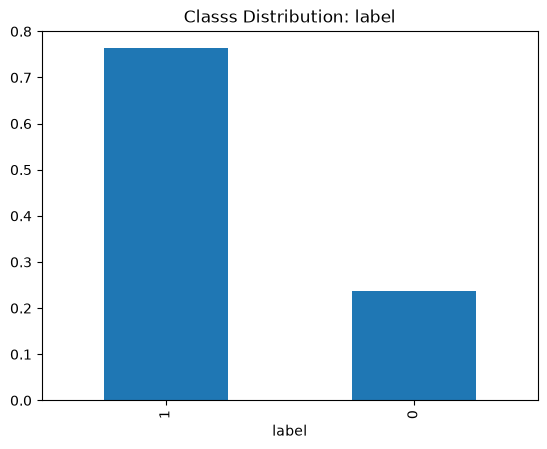

In [8]:
df["label"].value_counts()
df["label"].value_counts(normalize =True).plot(kind="bar", title = "Classs Distribution: label")

In [9]:
df["label"].value_counts(normalize=True).round(4)

label
1    0.7631
0    0.2369
Name: proportion, dtype: float64

**Q5.** Replace the `-` placeholders with NaN and list the percentage of missing values per column.

In [10]:
df = df.replace("-", np.nan)
df.head()

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,NaN,290.371539,101568,2592,OTH,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000102,0,0,REJ,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000148,0,0,REJ,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000113,0,0,REJ,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000130,0,0,REJ,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor


In [11]:
# Missing values per column
missing_counts = df.isnull().sum()
print(missing_counts)

src_ip                         0
src_port                       0
dst_ip                         0
dst_port                       0
proto                          0
service                   132032
duration                       0
src_bytes                      0
dst_bytes                      0
conn_state                     0
missed_bytes                   0
src_pkts                       0
src_ip_bytes                   0
dst_pkts                       0
dst_ip_bytes                   0
dns_query                 176198
dns_qclass                     0
dns_qtype                      0
dns_rcode                      0
dns_AA                    176030
dns_RD                    176030
dns_RA                    176030
dns_rejected              176030
ssl_version               210642
ssl_cipher                210642
ssl_resumed               210642
ssl_established           210642
ssl_subject               211032
ssl_issuer                211032
http_trans_depth          210740
http_metho

In [12]:

missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

src_ip                     0.000000
src_port                   0.000000
dst_ip                     0.000000
dst_port                   0.000000
proto                      0.000000
service                   62.561658
duration                   0.000000
src_bytes                  0.000000
dst_bytes                  0.000000
conn_state                 0.000000
missed_bytes               0.000000
src_pkts                   0.000000
src_ip_bytes               0.000000
dst_pkts                   0.000000
dst_ip_bytes               0.000000
dns_query                 83.489147
dns_qclass                 0.000000
dns_qtype                  0.000000
dns_rcode                  0.000000
dns_AA                    83.409542
dns_RD                    83.409542
dns_RA                    83.409542
dns_rejected              83.409542
ssl_version               99.809991
ssl_cipher                99.809991
ssl_resumed               99.809991
ssl_established           99.809991
ssl_subject               99

In [13]:
for i in missing_percentage.index:
    if missing_percentage[i] > 95:
        print(f"Column '{i}' has more than 95% missing values and will be dropped.")

Column 'ssl_version' has more than 95% missing values and will be dropped.
Column 'ssl_cipher' has more than 95% missing values and will be dropped.
Column 'ssl_resumed' has more than 95% missing values and will be dropped.
Column 'ssl_established' has more than 95% missing values and will be dropped.
Column 'ssl_subject' has more than 95% missing values and will be dropped.
Column 'ssl_issuer' has more than 95% missing values and will be dropped.
Column 'http_trans_depth' has more than 95% missing values and will be dropped.
Column 'http_method' has more than 95% missing values and will be dropped.
Column 'http_uri' has more than 95% missing values and will be dropped.
Column 'http_version' has more than 95% missing values and will be dropped.
Column 'http_user_agent' has more than 95% missing values and will be dropped.
Column 'http_orig_mime_types' has more than 95% missing values and will be dropped.
Column 'http_resp_mime_types' has more than 95% missing values and will be dropped

In [14]:
missing_columns = missing_percentage[missing_percentage >95].index.tolist()
print(missing_columns)

['ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri', 'http_version', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice']


In [15]:
count = len(missing_columns)
print(count)

16


## 4. Clean the data
**Q6.** Drop the columns that are more than 95% empty. How many were dropped?

In [16]:
df.shape

(211043, 44)

In [17]:
df = df.drop(columns=missing_columns)

In [18]:
df.shape

(211043, 28)

**Q7.** Drop the identifier columns (`src_ip`, `dst_ip`, `src_port`, `dst_port`). Why do they cause overfitting?

In [19]:
# We dropped them beacuse a tree that memorized them would not work on a different network
df = df.drop(columns=["src_ip","dst_ip","src_port","dst_port"])

In [20]:
df.shape

(211043, 24)

**Q8.** How many duplicate rows are there now?

In [21]:
no_of_duplicates = df.duplicated().sum()
print(no_of_duplicates)

117159


In [22]:
if DEDUPLICATE:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Rows after duplicates removed:", df.duplicated().sum())

## 5. Targets and split
**Q9.** Build the features `X` and the target `y` (`label`), without the other target column (leakage). Split 80/20 with stratification. Do the class shares match between train and test?

In [23]:
X = df.drop(columns=["label","type"])
y = df["label"]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=RANDOM_STATE, stratify=df["type"])

In [24]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(168834, 22) (42209, 22) (168834,) (42209,)


In [25]:
# Class shares should be (almost) the same in train and test
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).round(4)

,train,test
label,,
1,0.7631,0.7631
0,0.2369,0.2369


## 6. Encode and scale the features
**Q10.** Encode the categorical columns using the training set only: missing values as their own category, one-hot for low-cardinality columns, frequency encoding for `dns_query`. Why are the encoders fitted after the split?

In [26]:
# Encoders learn ONLY from the training set, then are applied to the test set.
onehot_cols = ["proto", "service", "conn_state", "dns_AA", "dns_RD", "dns_RA", "dns_rejected"]
freq_col = "dns_query"   # 700+ different values: one-hot would add too many columns

X_train = X_train.copy()
X_test = X_test.copy()

# Missing values in categorical columns become their own category
for c in onehot_cols + [freq_col]:
    X_train[c] = X_train[c].fillna("missing")
    X_test[c] = X_test[c].fillna("missing")

# Frequency encoding for dns_query (frequencies from the training set only)
freq_map = X_train[freq_col].value_counts(normalize=True)
X_train[freq_col] = X_train[freq_col].map(freq_map)
X_test[freq_col] = X_test[freq_col].map(freq_map).fillna(0)   # unseen in training -> 0

# One-hot encoding; the test set is aligned to the training columns
X_train = pd.get_dummies(X_train, columns=onehot_cols).astype(float)
X_test = pd.get_dummies(X_test, columns=onehot_cols).reindex(columns=X_train.columns, fill_value=0).astype(float)

X_train.shape, X_test.shape

((168834, 52), (42209, 52))

In [27]:
# Any NaN left after encoding? (train, test)
X_train.isna().any().any(), X_test.isna().any().any()

(np.False_, np.False_)

**Q11.** Scale the features with `StandardScaler`. Why does a neural network need scaling, and why is the scaler fitted on the training set only?

In [28]:
# Neural networks need features on the same scale (trees did not); the scaler learns mean/std from the training set only
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
X_train_s.shape, X_test_s.shape

((168834, 52), (42209, 52))

## 7. Validation with stratified 5-fold
**Q12.** Run stratified 5-fold validation with the fixed hyperparameters. Is the validation score stable across the folds?

In [29]:
# 5 rounds on the 80%: each round trains on 4 parts (64% of all data) and validates on 1 part (16%)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_scores = []
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):
    # A fresh scaler per fold, fitted on the fold's training part only (the validation part stays unseen)
    sc = StandardScaler()
    X_tr = sc.fit_transform(X_train.iloc[train_idx])
    X_va = sc.transform(X_train.iloc[val_idx])
    m = MLPClassifier(**HP)
    m.fit(X_tr, y_train.iloc[train_idx])
    pred = m.predict(X_va)
    fold_scores.append({"fold": fold, "epochs": m.n_iter_,
                        "val_accuracy": accuracy_score(y_train.iloc[val_idx], pred),
                        "val_f1": f1_score(y_train.iloc[val_idx], pred)})

fold_df = pd.DataFrame(fold_scores).set_index("fold")
fold_df.round(4)

,epochs,val_accuracy,val_f1
fold,,,
1,50,0.9921,0.9949
2,50,0.9914,0.9944
3,50,0.9911,0.9942
4,50,0.9921,0.9948
5,50,0.9930,0.9954


In [30]:
# Mean and spread over the 5 folds (small std = stable model)
fold_df.agg(["mean", "std"]).round(4)

,epochs,val_accuracy,val_f1
mean,50.0,0.9919,0.9947
std,0.0,0.0007,0.0005


## 8. Final model
**Q13.** Train the final model on the full training set. How long does it take? How many epochs did it run, and how many weights does the network have?

In [31]:
model = MLPClassifier(**HP)

start = time.perf_counter()
model.fit(X_train_s, y_train)
train_time = time.perf_counter() - start

# Epochs actually run, and the number of learned weights + biases in the network
n_weights = sum(w.size for w in model.coefs_) + sum(b.size for b in model.intercepts_)
train_time, model.n_iter_, n_weights

(49.96498230000725, 50, 17153)

## 9. Evaluation on the test set (used once)
**Q14.** Predict on the test set and measure the inference latency (ms per sample).

In [32]:
# Latency = predict() time on the whole test set / number of test rows, in ms per sample
start = time.perf_counter()
y_pred = model.predict(X_test_s)
latency_ms = (time.perf_counter() - start) / len(X_test_s) * 1000

# Probabilities are needed for ROC-AUC and Log-Loss
y_proba = model.predict_proba(X_test_s)
latency_ms

0.0022105522516315877

**Q15.** Compute Accuracy, Precision, Recall, F1, ROC-AUC, Log-Loss, FPR, MCC and TP/TN/FP/FN.

In [33]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba[:, 1])   # column 1 = probability of "attack"
logloss = log_loss(y_test, y_proba)
mcc = matthews_corrcoef(y_test, y_pred)

# ravel() unpacks the 2x2 matrix in this order: TN, FP, FN, TP
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
fpr = fp / (fp + tn)   # share of normal traffic wrongly flagged as attack

pd.Series({"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1,
           "ROC-AUC": roc_auc, "Log-Loss": logloss, "FPR": fpr, "MCC": mcc}).round(4)

Accuracy     0.9923
Precision    0.9933
Recall       0.9966
F1           0.9949
ROC-AUC      0.9982
Log-Loss     0.0333
FPR          0.0217
MCC          0.9786
dtype: float64

In [34]:
tp, tn, fp, fn

(np.int64(32100), np.int64(9783), np.int64(217), np.int64(109))

**Q16.** Compare the train and test accuracy. Is the network overfitting or underfitting?

In [35]:
# Train much higher than test = overfitting; both low and close = underfitting
train_acc = accuracy_score(y_train, model.predict(X_train_s))
test_acc = accuracy_score(y_test, y_pred)
round(train_acc, 4), round(test_acc, 4)

(0.9927, 0.9923)

## 10. Visualizations
**Q17.** Plot the confusion matrix and the ROC curve.

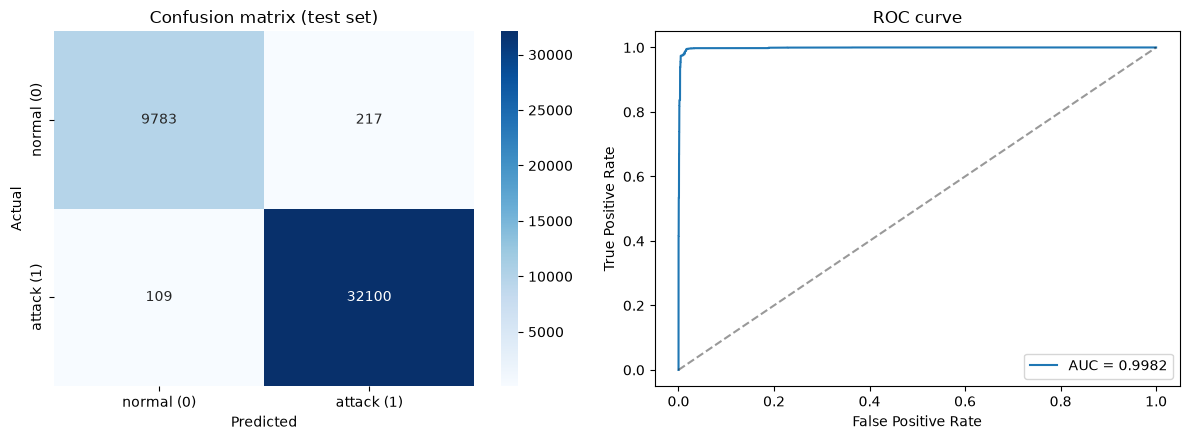

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["normal (0)", "attack (1)"], yticklabels=["normal (0)", "attack (1)"])
ax[0].set(title="Confusion matrix (test set)", xlabel="Predicted", ylabel="Actual")

fpr_curve, tpr_curve, _ = roc_curve(y_test, y_proba[:, 1])
ax[1].plot(fpr_curve, tpr_curve, label=f"AUC = {roc_auc:.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4)   # a random guess would follow this line
ax[1].set(title="ROC curve", xlabel="False Positive Rate", ylabel="True Positive Rate")
ax[1].legend()

plt.tight_layout()
plt.show()

**Q18.** Plot the training loss per epoch. Did the training stop before the last epoch?

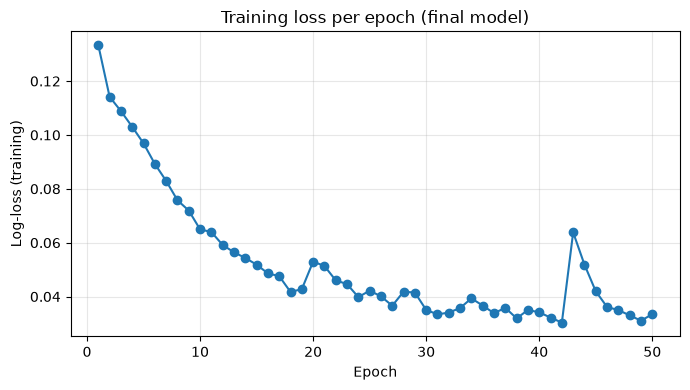

In [37]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(model.loss_curve_) + 1), model.loss_curve_, marker="o")
plt.title("Training loss per epoch (final model)")
plt.xlabel("Epoch"); plt.ylabel("Log-loss (training)")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 11. Results table
**Q19.** Collect all the numbers in one results table.

In [38]:
results = pd.DataFrame([{
    "Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1-Score": f1,
    "ROC-AUC": roc_auc, "Log-Loss": logloss, "FPR": fpr, "MCC": mcc,
    "Inference Latency (ms/sample)": latency_ms, "Training time (s)": train_time,
    "Test time (s)": latency_ms * len(y_test) / 1000,
    "TP": tp, "TN": tn, "FP": fp, "FN": fn,
    "Test rows": len(y_test),
}], index=["ANN - label"])
results.T

,ANN - label
Accuracy,0.992277
Precision,0.993285
Recall,0.996616
F1-Score,0.994948
ROC-AUC,0.998204
Log-Loss,0.033308
FPR,0.021700
MCC,0.978584
Inference Latency (ms/sample),0.002211
Training time (s),49.964982


## 12. Discussion (for the report)
**Q20.** How does the ANN compare with the Decision Tree on this target (accuracy, F1, MCC, inference latency, training time)?

**Q21.** Which kind of error matters more here, false positives or false negatives, and what does the model's FPR say?

**Q22.** How does the class imbalance affect the results?

**Q23.** What are the limitations of this model?